## Importação das bibliotecas e configurações iniciais

In [ ]:
import torch
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO
from roboflow import Roboflow
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"

Importação do Dataset via Roboflow

In [ ]:
rf = Roboflow(api_key="fIDplCWZTIrrQ2z3vZRP")
project = rf.workspace("roboflow-100").project("brain-tumor-m2pbp")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to brain-tumor-2 in yolov8:: 100%|██████████| 19812/19812 [00:01<00:00, 11328.93it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Carregamento, configuração e treinamento do modelo "yolov8n.pt"

In [ ]:
model = YOLO('yolov8n.pt')

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    workers=2,
    device=0
)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/brain-tumor-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opti

## Teste de confiança do modelo para diferentes limiares de confiança

In [ ]:
best_model = YOLO('runs/detect/train/weights/best.pt')
test_img_dir = os.path.join(dataset.location, 'test', 'images')

# Testa diferentes limiares de confiança
thresholds = [0.25, 0.40, 0.50, 0.60]

for thresh in thresholds:
    results = best_model.predict(source=test_img_dir, conf=thresh, verbose=False)

    total_detections = sum(len(r.boxes) for r in results)
    avg_conf = 0
    conf_list = [float(box.conf) for r in results for box in r.boxes]
    if conf_list:
        avg_conf = sum(conf_list) / len(conf_list)

    print(f"Limiar conf={thresh:.2f} | Total de Caixas Detectadas: {total_detections} | Confiança Média: {avg_conf:.2f}")

Limiar conf=0.25 | Total de Caixas Detectadas: 1683 | Confiança Média: 0.64
Limiar conf=0.40 | Total de Caixas Detectadas: 1385 | Confiança Média: 0.71
Limiar conf=0.50 | Total de Caixas Detectadas: 1246 | Confiança Média: 0.74
Limiar conf=0.60 | Total de Caixas Detectadas: 1050 | Confiança Média: 0.77


## Inferência e Validação do treino no dataset de teste

In [ ]:
test_results = best_model.predict(source=test_img_dir, conf=0.50, save=True)


image 1/990 /content/brain-tumor-2/test/images/volume_100_slice_105_jpg.rf.76d5a46d0268b812fb2d17702d2c68a2.jpg: 640x640 1 label1, 12.5ms
image 2/990 /content/brain-tumor-2/test/images/volume_100_slice_47_jpg.rf.1251a28a7dc734c97b852a8a7855d5ff.jpg: 640x640 1 label1, 13.4ms
image 3/990 /content/brain-tumor-2/test/images/volume_100_slice_48_jpg.rf.99cfad0e43aa2ff320e0e943d56d0d5d.jpg: 640x640 1 label1, 12.5ms
image 4/990 /content/brain-tumor-2/test/images/volume_100_slice_51_jpg.rf.fd8b915800706e464c3343da4e9fac05.jpg: 640x640 1 label1, 1 label2, 12.5ms
image 5/990 /content/brain-tumor-2/test/images/volume_101_slice_43_jpg.rf.0e109ebefc582671f100255115f194d5.jpg: 640x640 1 label1, 12.5ms
image 6/990 /content/brain-tumor-2/test/images/volume_101_slice_68_jpg.rf.048615aca0086d0db8a13ef552ab5f30.jpg: 640x640 1 label1, 12.5ms
image 7/990 /content/brain-tumor-2/test/images/volume_102_slice_119_jpg.rf.28c4c0edc48b9e01fb95bcd5ba98e9fd.jpg: 640x640 (no detections), 12.4ms
image 8/990 /content/

## Demonstração visual de resultados de identificação

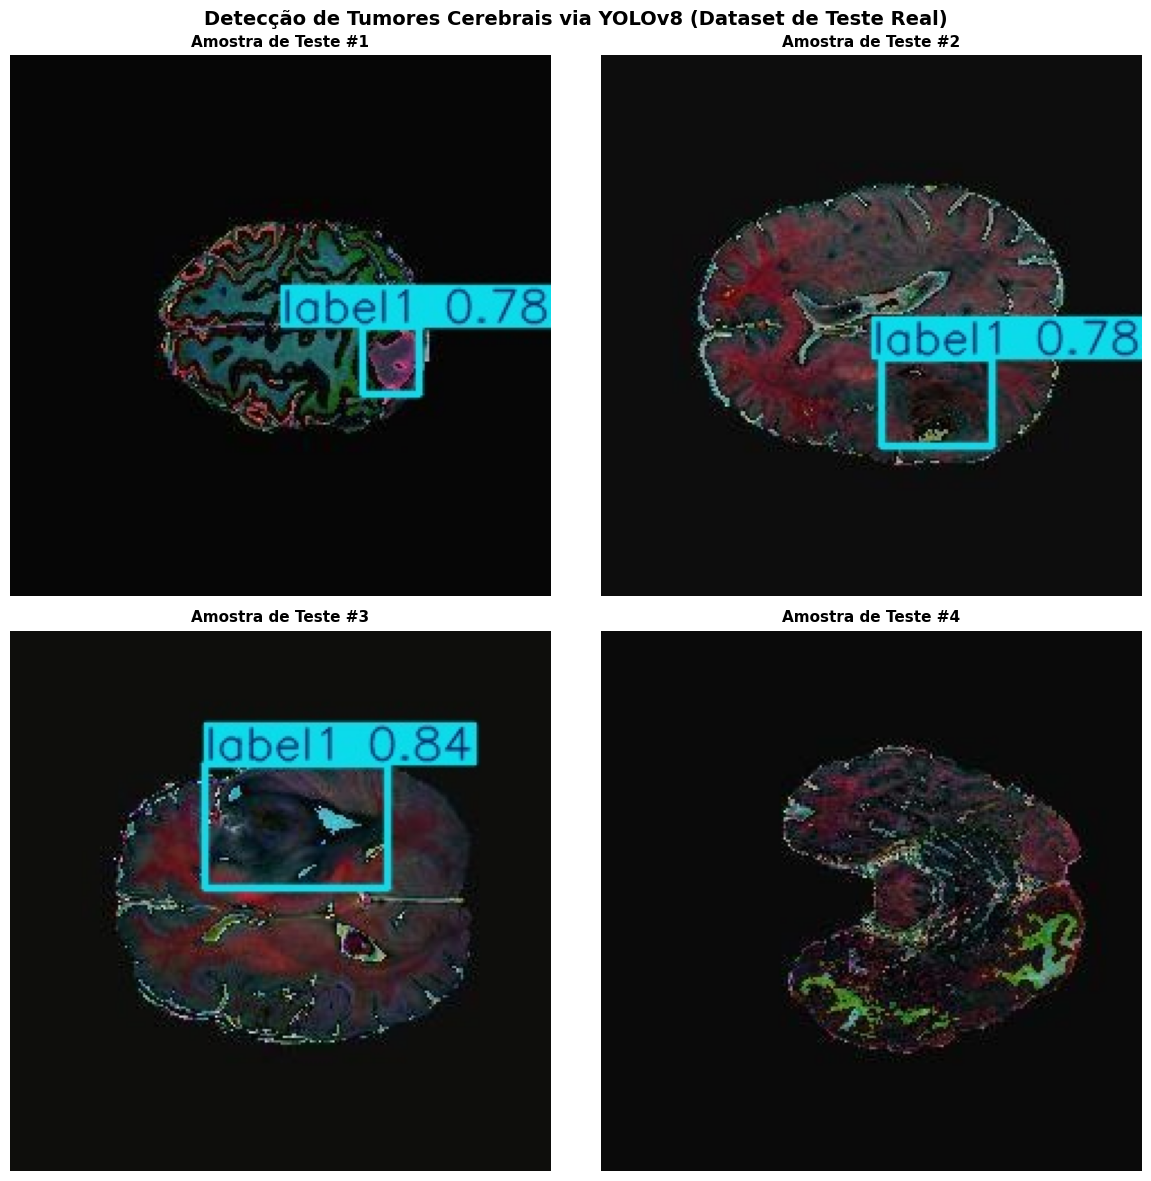

In [ ]:
predicted_files = glob.glob('runs/detect/predict/*.jpg') + glob.glob('runs/detect/predict/*.png')

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
fig.suptitle("Detecção de Tumores Cerebrais via YOLOv8 (Dataset de Teste Real)", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(predicted_files):
        img_path = predicted_files[i]
        img = Image.open(img_path)

        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Amostra de Teste #{i+1}", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## Demonstração da melhora do desempenho do modelo ao longo das épocas de treino

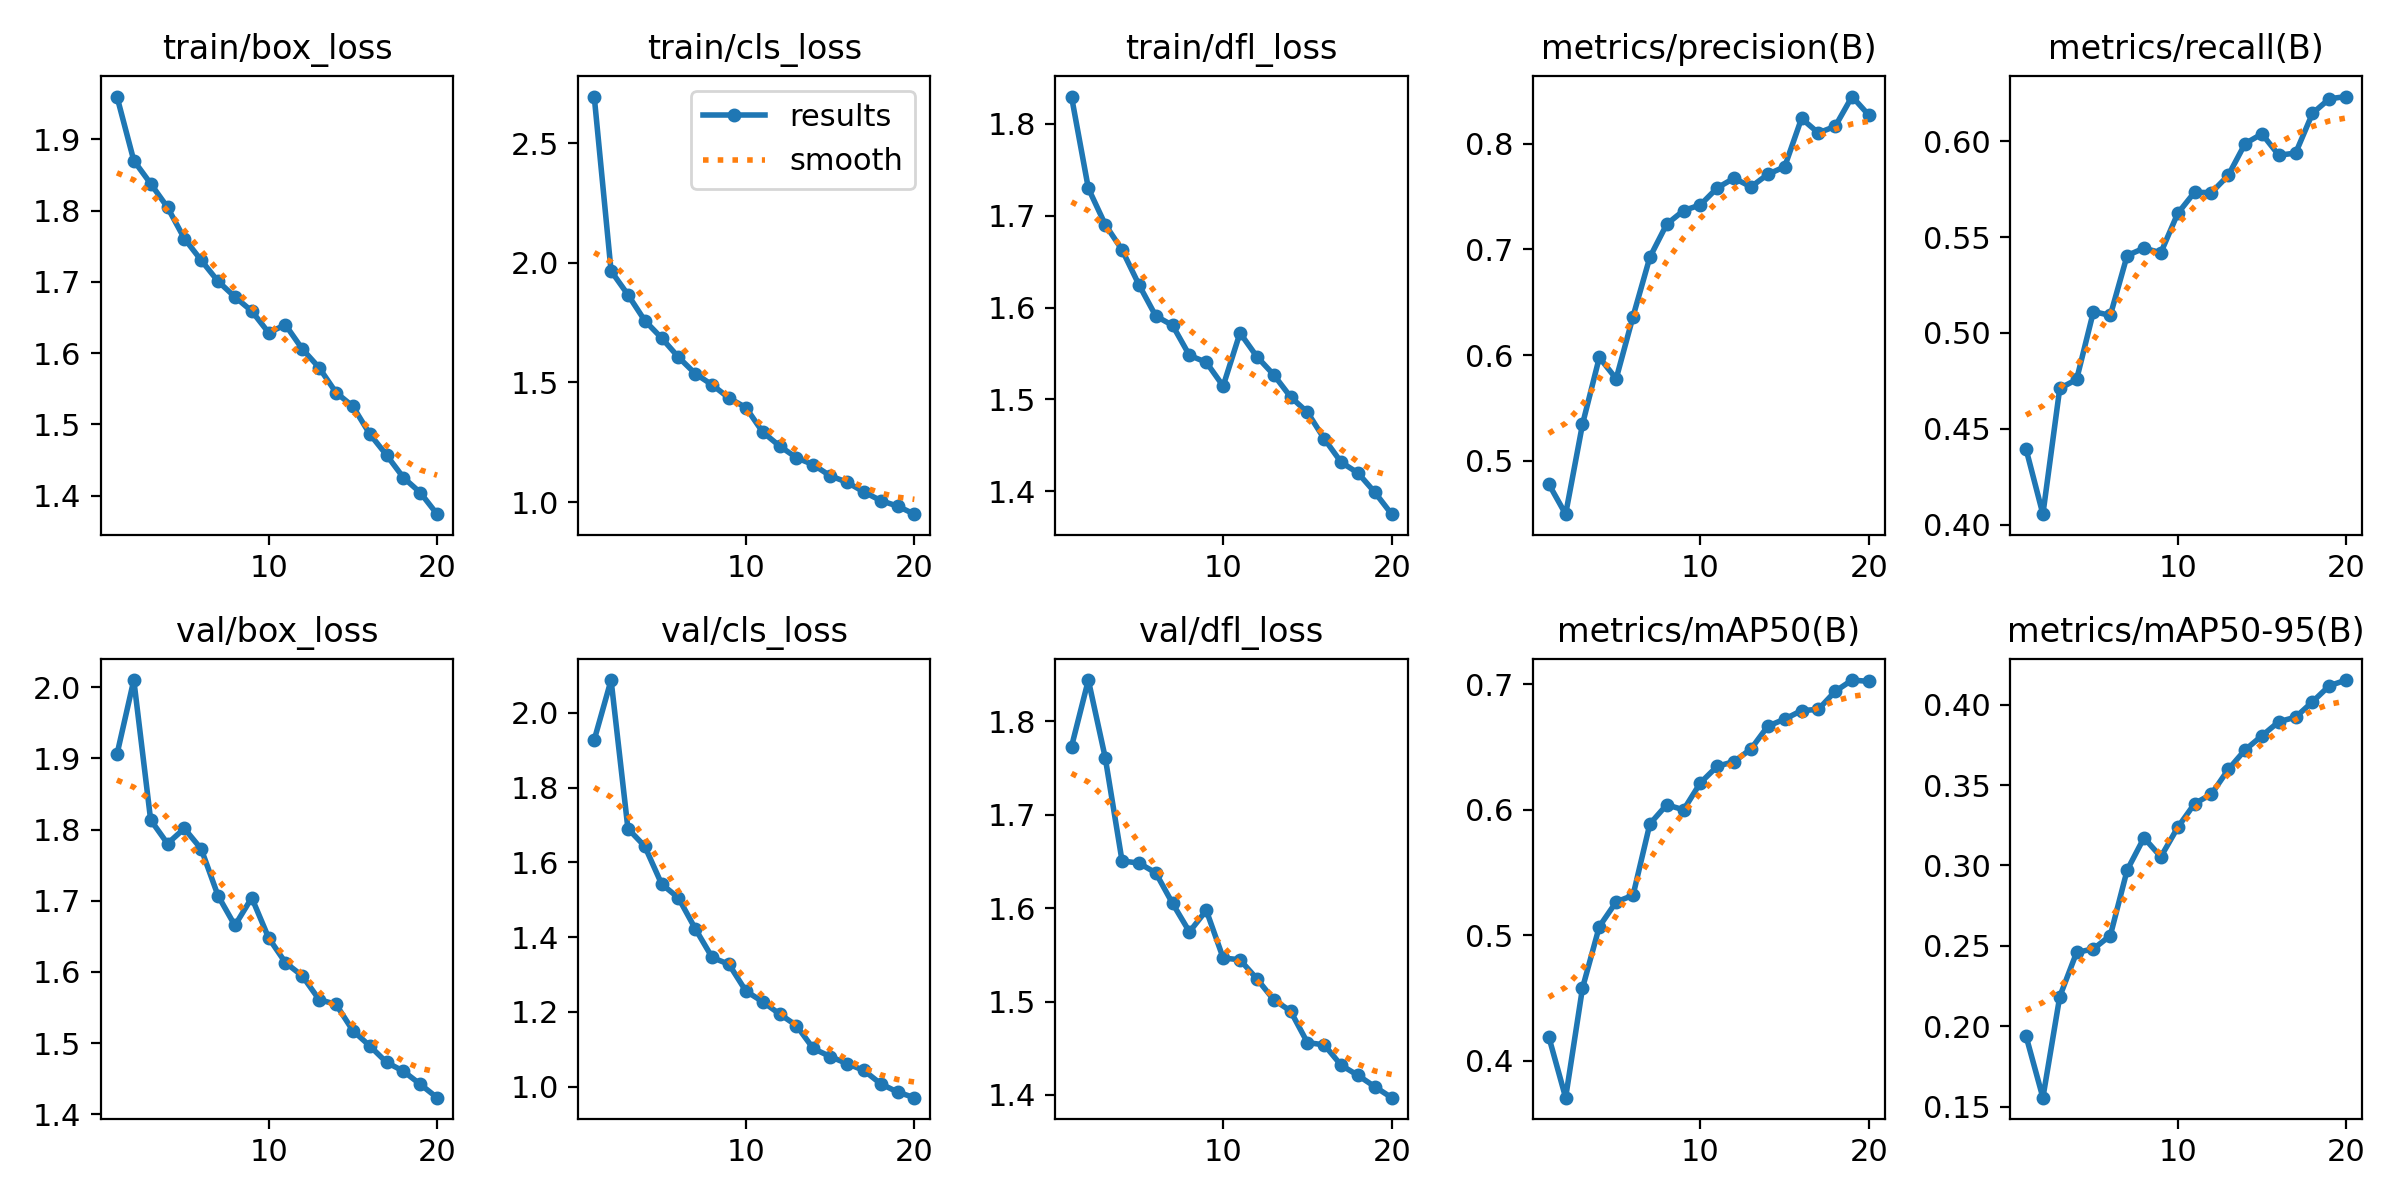

In [ ]:
display(Image.open('runs/detect/train/results.png'))

## Matriz de confusão de classificação do modelo para um Score de Confiança de 50%

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 377.3±144.9 MB/s, size: 6.2 KB)
val: Scanning /content/brain-tumor-2/test/labels... 990 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 990/990 1.7Kit/s 0.6s
val: New cache created: /content/brain-tumor-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 6.2it/s 10.0s
                   all        990       2150      0.923      0.505      0.501      0.324
                label0        608        608      0.895      0.352      0.346      0.194
                label1        979        979      0.938      0.682      0.678      0.471
                label2        563        563      0.934      0.481      0.479      0.309
Speed: 1.5ms preprocess, 4.5ms inference, 0.0ms loss, 1.0ms postprocess per

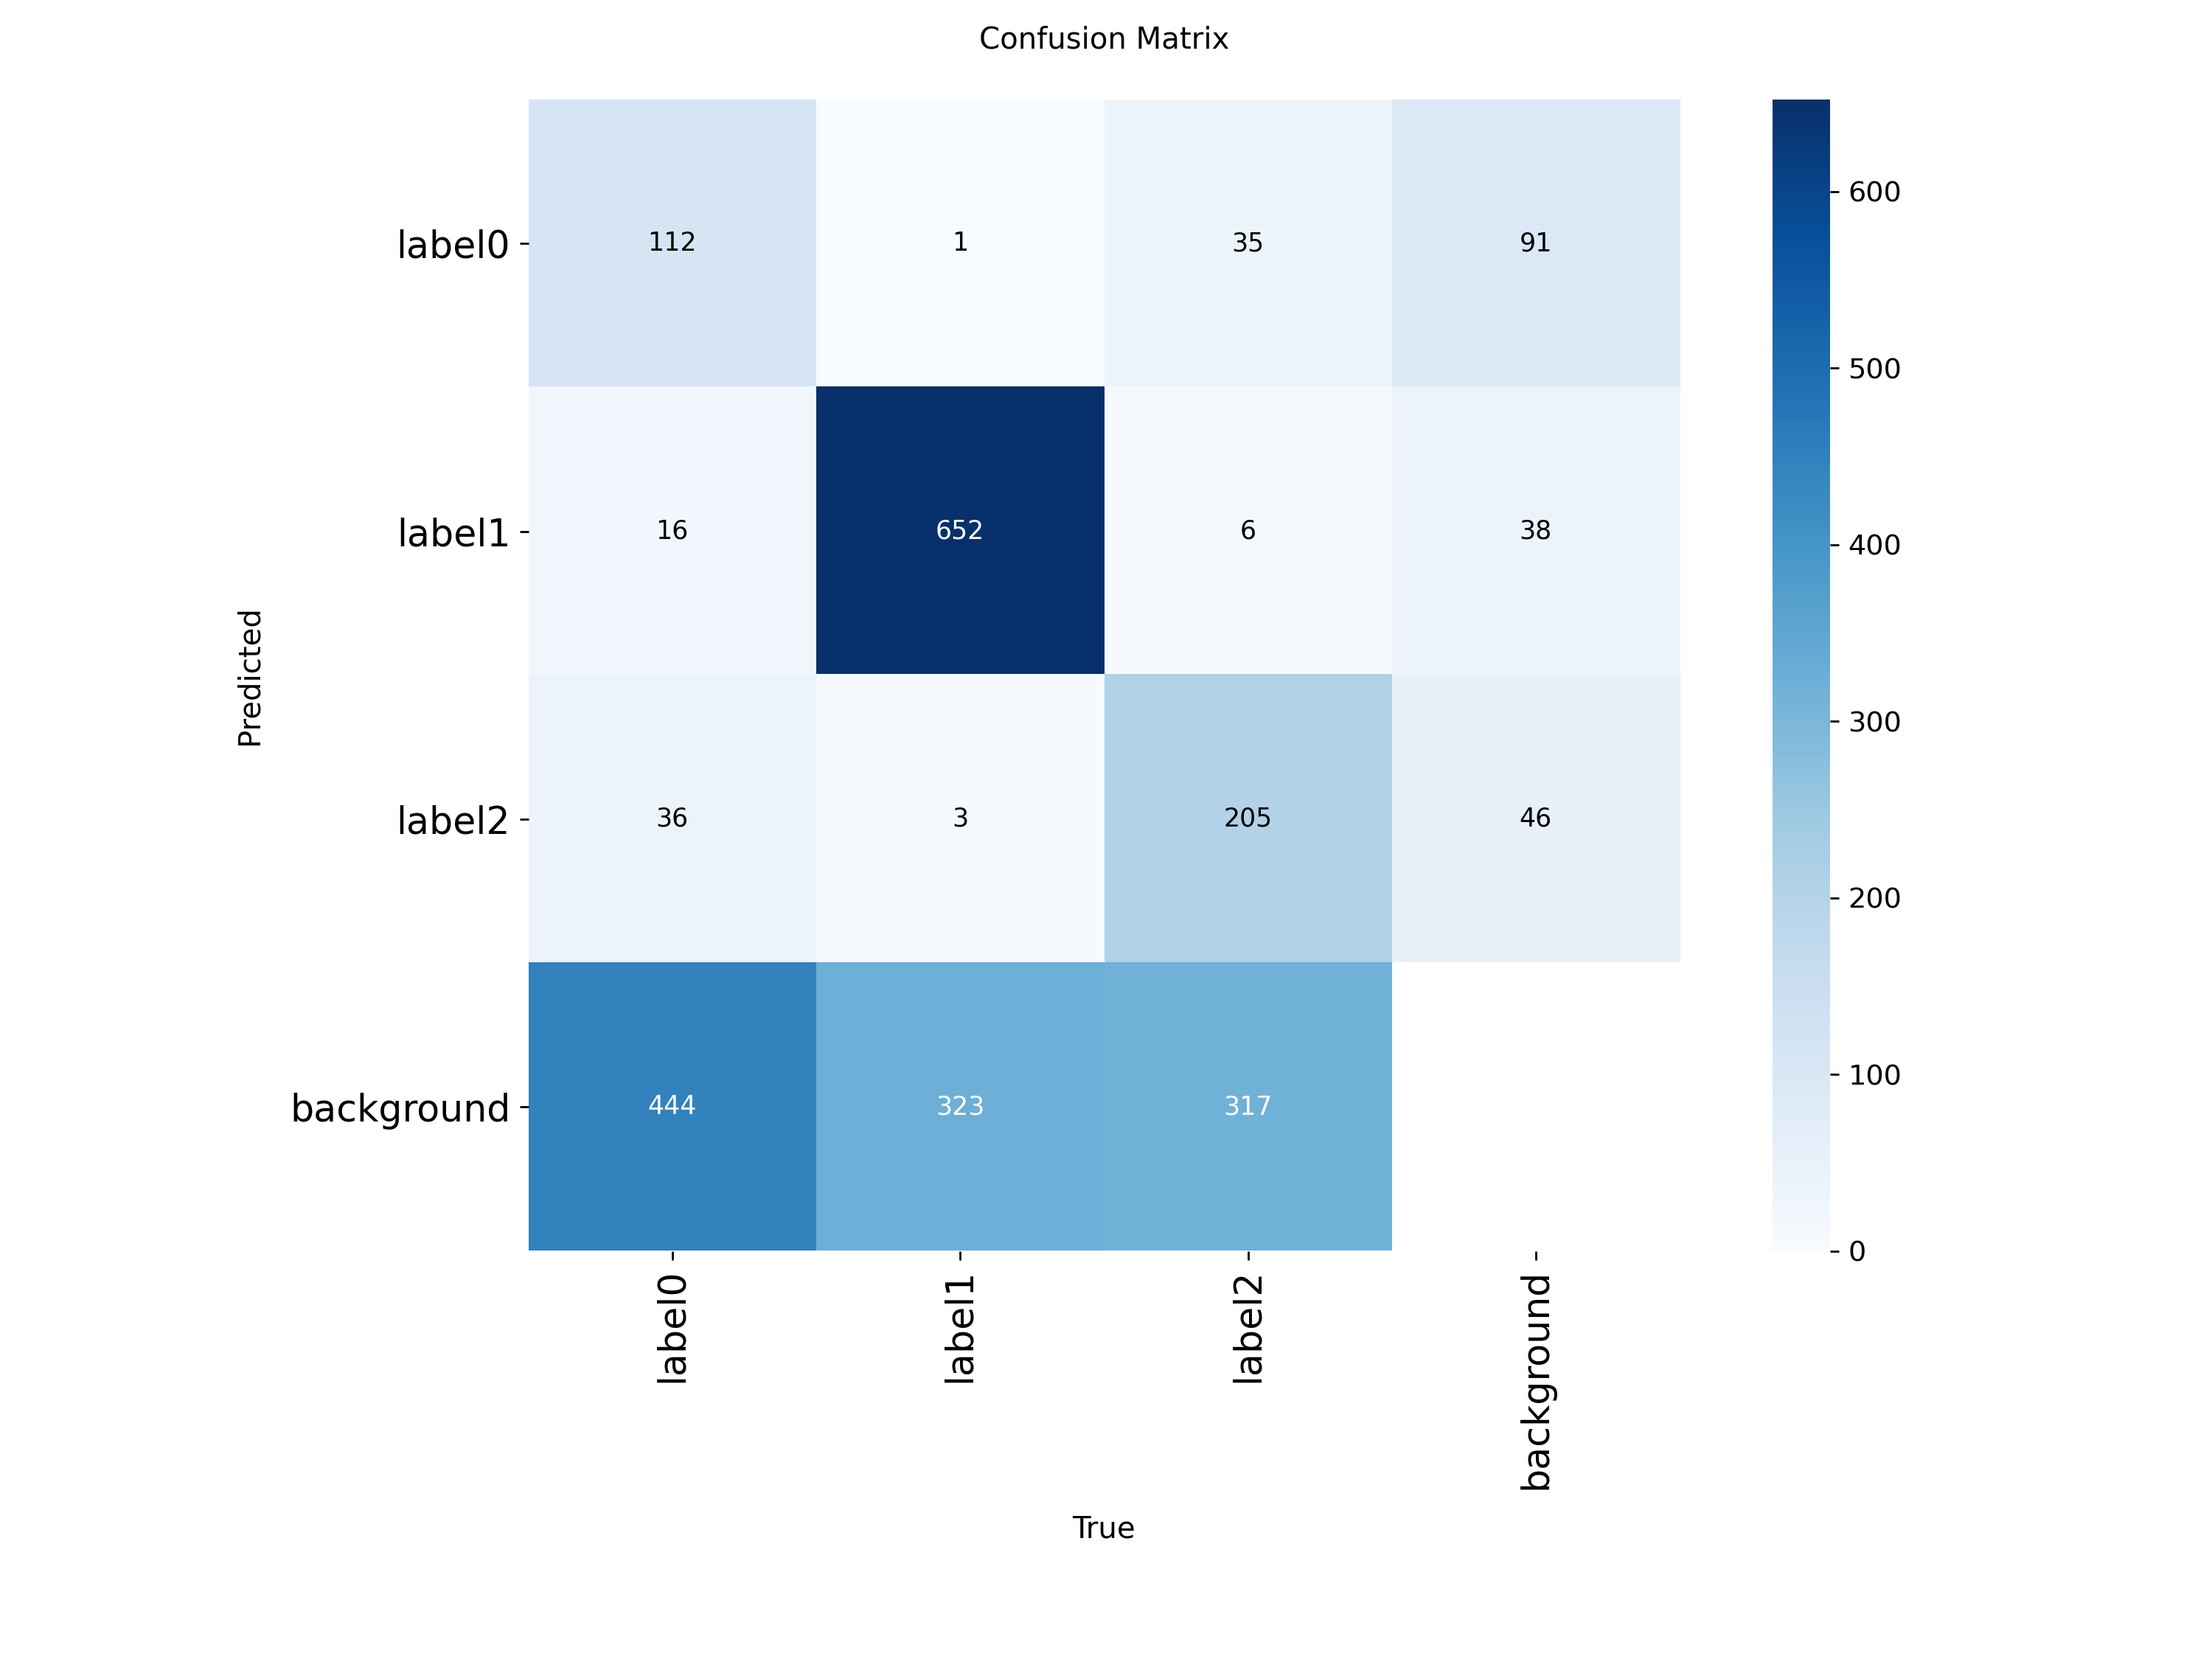

In [ ]:
metrics = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split='test',
    conf=0.50,
    name='val_conf_050'
)

new_matrix_path = 'runs/detect/val_conf_050/confusion_matrix.png'
if os.path.exists(new_matrix_path):
    display(Image(filename=new_matrix_path))